This notebook shows how to generate 100m x 100m grids from the eurostat 100km x 100km grid file

In [1]:
#module load ceuadmin/miniforge3/25.3.1-0


import geopandas as gpd
import os
from shapely.geometry import Polygon
from multiprocessing import Pool

In [58]:
# function to generate sub-grids within a given boundary
def create_grid(bounds, x_offset, y_offset, crs):
    """
    Creates a grid of polygons within the specified bounds with given x and y offsets.

    Args:
        bounds (dict): A dictionary containing the minx, miny, maxx, and maxy of the bounding box.
        x_offset (float): The horizontal distance between each grid line.
        y_offset (float): The vertical distance between each grid line.
        crs (str): The coordinate reference system to use for the resulting GeoDataFrame.

    Returns:
        GeoDataFrame: A GeoDataFrame containing polygons for each grid cell.
    """
    minx, miny, maxx, maxy = bounds['minx'], bounds['miny'], bounds['maxx'], bounds['maxy']
    grid_rows = []

    # calculate the number of cells in each direction
    x_cells = int((maxx - minx) / x_offset)
    y_cells = int((maxy - miny) / y_offset)

    # create grid cells
    for i in range(x_cells):
        for j in range(y_cells):
            cell_minx = minx + i * x_offset
            cell_miny = miny + j * y_offset
            cell_maxx = cell_minx + x_offset
            cell_maxy = cell_miny + y_offset

            grid_cell = Polygon([
                (cell_minx, cell_miny),
                (cell_maxx, cell_miny),
                (cell_maxx, cell_maxy),
                (cell_minx, cell_maxy)
            ])

            grid_rows.append({'geometry': grid_cell})

    # create GeoDataFrame from grid cells
    grid_gdf = gpd.GeoDataFrame(grid_rows, crs=crs)
    return grid_gdf

In [56]:
# function to create and assign sub-grids to parquet files
def create_and_assign_grid(index, row, x_offset, y_offset, crs):
    """
    Creates sub-grids for a given row and saves them to a file.

    Args:
        index (int): Index of the row.
        row (GeoSeries): Row containing geometry data.
        x_offset (float): Horizontal grid size.
        y_offset (float): Vertical grid size.
        crs (str): Coordinate reference system.

    Returns:
        tuple: The generated grid GeoDataFrame and the grid ID.
    """
    output_file = f'data/grids_100_{index+1}.parquet'

    if os.path.exists(output_file):
        print(f"Skipping grid {index+1} as it already exists.")
        return index + 1
    else:
        print(f"Processing grid {index+1}...")
        bounds = {
            'minx': row.geometry.bounds[0],
            'miny': row.geometry.bounds[1],
            'maxx': row.geometry.bounds[2],
            'maxy': row.geometry.bounds[3]
        }
        grid_gdf = create_grid(bounds, x_offset, y_offset, crs)
        grid_gdf['grid_100000_id'] = index + 1
        grid_gdf.to_parquet(output_file)

    return grid_gdf, index + 1

In [4]:
from shapely.geometry import Point

# read Eurostat 100km grid file: https://gisco-services.ec.europa.eu/grid/GISCO_grid_metadata.pdf 
eu_gdf = gpd.read_file('/rds/user/trpb2/hpc-work/walkability/walkability-obct/grid_100km_surf.gpkg')

In [3]:
# temporary step to find a UK grid

# CRS must match eu_gdf
pt = gpd.GeoSeries([Point(-0.1276, 51.5074)], crs="EPSG:4326").to_crs(eu_gdf.crs).iloc[0]

match = eu_gdf[eu_gdf.contains(pt)]
print(match.index.tolist())   # grid index/indices containing London point

[607]


In [54]:
countries = eu_gdf['CNTR_ID'].unique()
uk_entries = countries[["UK" in entry.split("-") for entry in countries]]
uk = eu_gdf[eu_gdf['CNTR_ID'].isin(uk_entries)]
# for mainland only
# uk = eu_gdf[eu_gdf['CNTR_ID'] == 'UK']
uk_ids = (uk.index).tolist()   # assumes a default RangeIndex
print(len(uk_ids), uk_ids[:10])

60 [528, 529, 564, 565, 566, 567, 568, 569, 571, 602]


In [3]:
# read  https://gisco-services.ec.europa.eu/grid/GISCO_grid_metadata.pdf 
eu_gdf = gpd.read_file('/rds/user/trpb2/hpc-work/walkability/walkability-obct/grid_100km_surf.gpkg')

# grid parameters
crs = eu_gdf.crs
x_offset = 100
y_offset = 100

# prepare data for parallel processing
# this is conditioned by index=610 which is an area that covers part of the Netherlands
# you can remove the if condition if you want to generate 100mx100m grids for all
# 100kmx100km grids
# the index here starts from 0 and in the func 'create_and_assign_grid' we add +1
# so that the files are named from 1 (personal preference)
data = [(index, row, x_offset, y_offset, crs) 
        for index, row in eu_gdf.iterrows() if index in uk_ids]

# ensure the output directory exists
output_directory = '/rds/user/trpb2/hpc-work/walkability/walkability-obct/grids'
if not os.path.exists(output_directory):
    os.makedirs(output_directory)

# for testing as we are only generating it for one grid,
# we can process it in sequence
for elem in data:
    create_and_assign_grid(*elem)
    
# # or process grids in parallel
# with Pool() as pool:
#     results = pool.starmap(create_and_assign_grid, data)

ERROR 1: PROJ: proj_create_from_database: Open of /home/trpb2/.conda/envs/geo_env/share/proj failed


NameError: name 'uk_ids' is not defined

In [6]:
countries = eu_gdf['CNTR_ID'].unique()
uk_entries = countries[["UK" in entry.split("-") for entry in countries]]
uk_entries

array(['UK', 'FR-BE-UK', 'IE-UK', 'IM-UK'], dtype=object)

60 [528, 529, 564, 565, 566, 567, 568, 569, 571, 602]


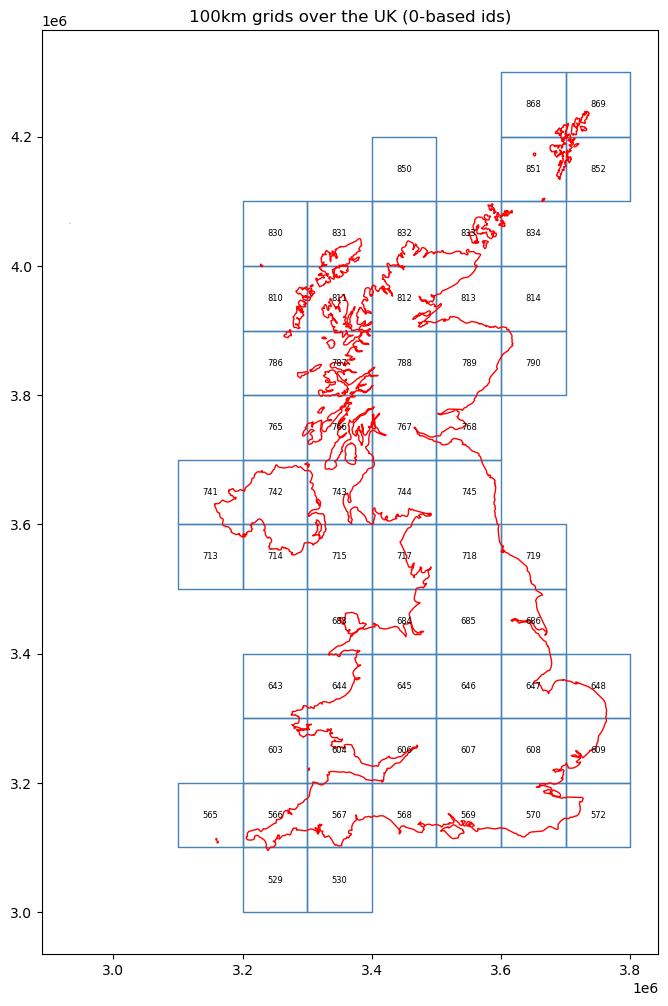

In [13]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

uk = eu_gdf[eu_gdf['CNTR_ID'].isin(uk_entries)]
# uk = eu_gdf[eu_gdf['CNTR_ID'] == 'UK']
uk_ids = (uk.index).tolist()   # assumes a default RangeIndex
print(len(uk_ids), uk_ids[:10])

fig, ax = plt.subplots(figsize=(8, 12))
uk.plot(ax=ax, facecolor='none', edgecolor='steelblue')

# label each tile with its 1-based id
for idx, row in uk.iterrows():
    c = row.geometry.centroid
    ax.annotate(idx+1, (c.x, c.y), ha='center', va='center', fontsize=6)

ax.set_title('100km grids over the UK (0-based ids)')


# For a real coastline, overlay a UK boundary. Use the Natural Earth countries file, or any UK shapefile, reprojected to 3035:

world = gpd.read_file('data/UK/ne_10m_admin_0_countries.shp')  # or ne_10m for more detail
#uk = gpd.read_file('data/UK/ne_10m_admin_0_countries_ukr.shp').to_crs(eu_gdf.crs)  # or ne_10m for more detail
uk_plot = world[world['ADMIN'] == 'United Kingdom'].to_crs(eu_gdf.crs)
uk_plot.plot(ax=ax, facecolor='none', edgecolor='red')

plt.show()

In [12]:
uk

,DIST_BORD,TOT_P_2018,TOT_P_2006,GRD_ID,TOT_P_2011,TOT_P_2021,Y_LLC,CNTR_ID,NUTS2016_3,NUTS2016_2,...,NUTS2021_3,NUTS2021_2,DIST_COAST,NUTS2021_1,NUTS2021_0,NUTS2024_3,NUTS2024_2,NUTS2024_1,NUTS2024_0,geometry
528,510326.562500,1780.0,1802.0,CRS3035RES100000mN3000000E3200000,1610.0,0.0,3000000,UK,UKK30,UKK3,...,UKK30,UKK3,46811.660156,UKK,UK,,,,,"POLYGON ((3200000 3000000, 3300000 3000000, 33..."
529,454553.843750,0.0,0.0,CRS3035RES100000mN3000000E3300000,0.0,0.0,3000000,UK,UKK43,UKK4,...,UKK43,UKK4,51460.750000,UKK,UK,,,,,"POLYGON ((3300000 3000000, 3400000 3000000, 34..."
564,421634.500000,2250.0,2126.0,CRS3035RES100000mN3100000E3100000,2203.0,0.0,3100000,UK,UKK30,UKK3,...,UKK30,UKK3,36586.980469,UKK,UK,,,,,"POLYGON ((3100000 3100000, 3200000 3100000, 32..."
565,410342.062500,453134.0,416984.0,CRS3035RES100000mN3100000E3200000,423333.0,0.0,3100000,UK,UKK30,UKK3,...,UKK30,UKK3,40399.261719,UKK,UK,,,,,"POLYGON ((3200000 3100000, 3300000 3100000, 33..."
566,420434.062500,1219182.0,1149684.0,CRS3035RES100000mN3100000E3300000,1161923.0,0.0,3100000,UK,UKK23-UKK30-UKK41-UKK42-UKK43,UKK2-UKK3-UKK4,...,UKK23-UKK30-UKK41-UKK42-UKK43,UKK2-UKK3-UKK4,28732.429688,UKK,UK,,,,,"POLYGON ((3300000 3100000, 3400000 3100000, 34..."
567,350098.625000,1399087.0,1282665.0,CRS3035RES100000mN3100000E3400000,1339812.0,0.0,3100000,UK,UKJ36-UKK15-UKK21-UKK22-UKK23-UKK43,UKJ3-UKK1-UKK2-UKK4,...,UKJ36-UKK15-UKK23-UKK24-UKK25-UKK43,UKJ3-UKK1-UKK2-UKK4,20750.679688,UKJ-UKK,UK,,,,,"POLYGON ((3400000 3100000, 3500000 3100000, 35..."
568,250222.218750,3389539.0,3123007.0,CRS3035RES100000mN3100000E3500000,3243574.0,0.0,3100000,UK,UKI74-UKI75-UKJ11-UKJ25-UKJ26-UKJ27-UKJ28-UKJ3...,UKI7-UKJ1-UKJ2-UKJ3-UKK1-UKK2,...,UKI74-UKI75-UKJ11-UKJ25-UKJ26-UKJ27-UKJ28-UKJ3...,UKI7-UKJ1-UKJ2-UKJ3-UKK1-UKK2,13152.870117,UKI-UKJ-UKK,UK,,,,,"POLYGON ((3500000 3100000, 3600000 3100000, 36..."
569,150510.062500,6073963.0,5401723.0,CRS3035RES100000mN3100000E3600000,5727310.0,0.0,3100000,UK,UKH31-UKH32-UKH37-UKI33-UKI34-UKI41-UKI42-UKI4...,UKH3-UKI3-UKI4-UKI5-UKI6-UKI7-UKJ2-UKJ4,...,UKH31-UKH32-UKH37-UKI33-UKI34-UKI41-UKI42-UKI4...,UKH3-UKI3-UKI4-UKI5-UKI6-UKI7-UKJ2-UKJ4,25591.650391,UKH-UKI-UKJ,UK,,,,,"POLYGON ((3600000 3100000, 3700000 3100000, 37..."
571,51917.261719,990274.0,941323.0,CRS3035RES100000mN3100000E3700000,965724.0,546631.0,3100000,FR-BE-UK,BE253-BE258-FRE11-FRE12-UKJ44,BE25-FRE1-UKJ4,...,BE253-BE258-FRE11-FRE12-UKJ44,BE25-FRE1-UKJ4,28357.960938,BE2-FRE-UKJ,BE-FR-UK,BE253-BE258-FRE11-FRE12,BE25-FRE1,BE2-FRE,BE-FR,"POLYGON ((3700000 3100000, 3800000 3100000, 38..."
602,310367.531250,67220.0,61798.0,CRS3035RES100000mN3200000E3200000,64853.0,0.0,3200000,UK,UKL14,UKL1,...,UKL14,UKL1,44303.820312,UKL,UK,,,,,"POLYGON ((3200000 3200000, 3300000 3200000, 33..."


52 [528, 529, 564, 565, 566, 567, 568, 569, 602, 603]


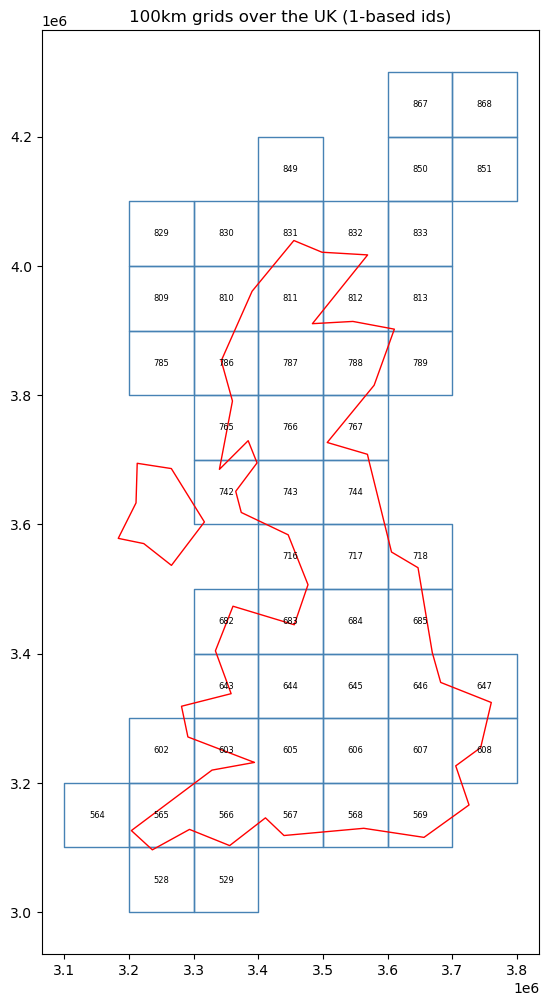

In [60]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box


uk = eu_gdf[eu_gdf['CNTR_ID'] == 'UK']
uk_ids = (uk.index).tolist()   # assumes a default RangeIndex
print(len(uk_ids), uk_ids[:10])

fig, ax = plt.subplots(figsize=(8, 12))
uk.plot(ax=ax, facecolor='none', edgecolor='steelblue')

# label each tile with its 1-based id
for idx, row in uk.iterrows():
    c = row.geometry.centroid
    ax.annotate(idx, (c.x, c.y), ha='center', va='center', fontsize=6)

ax.set_title('100km grids over the UK (0-based ids)')


# For a real coastline, overlay a UK boundary. Use the Natural Earth countries file, or any UK shapefile, reprojected to 3035:

world = gpd.read_file('data/UK/ne_110m_admin_0_countries.shp')  # or ne_10m for more detail
uk = world[world['ADMIN'] == 'United Kingdom'].to_crs(eu_gdf.crs)
uk.plot(ax=ax, facecolor='none', edgecolor='red')

plt.show()

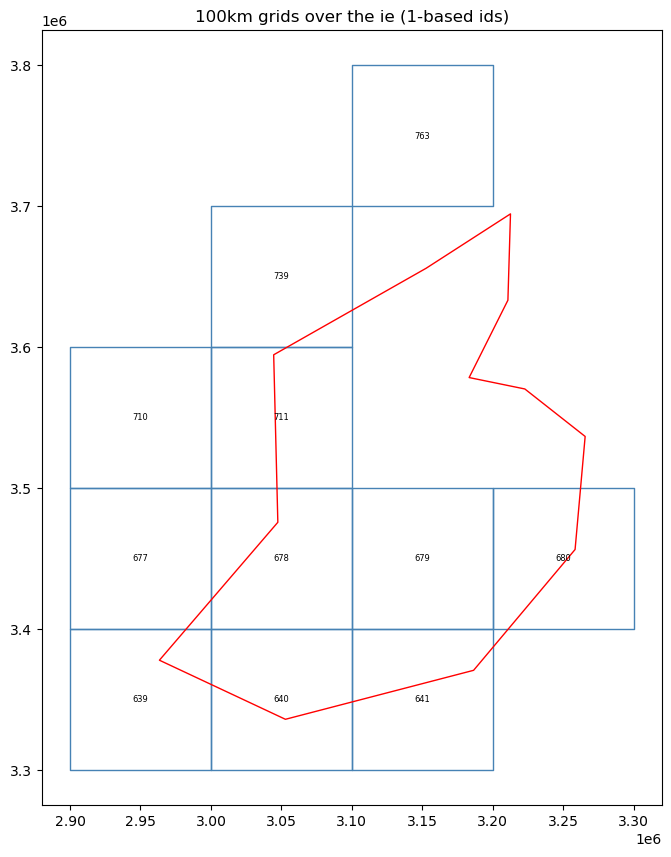

In [36]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

ie = eu_gdf[eu_gdf['CNTR_ID'] == 'IE']

fig, ax = plt.subplots(figsize=(8, 12))
ie.plot(ax=ax, facecolor='none', edgecolor='steelblue')

# label each tile with its 1-based id
for idx, row in ie.iterrows():
    c = row.geometry.centroid
    ax.annotate(idx, (c.x, c.y), ha='center', va='center', fontsize=6)

ax.set_title('100km grids over the ie (1-based ids)')


# For a real coastline, overlay a UK boundary. Use the Natural Earth countries file, or any UK shapefile, reprojected to 3035:

world = gpd.read_file('data/UK/ne_110m_admin_0_countries.shp')  # or ne_10m for more detail
uk = world[world['ADMIN'] == 'Ireland'].to_crs(eu_gdf.crs)
uk.plot(ax=ax, facecolor='none', edgecolor='red')

plt.show()